# Purpose : Algorithm to predict house price | Supervised | Regression

# Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## 1. Pandas Wrangling

In [ ]:
df = pd.read_csv("HousePrice.csv") #read dataset

In [ ]:
#head and tail
display(df.head())
display(df.tail())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41,6.984127,1.023810,322,50.000000,37.88,-122.23,4.526
1,8.3014,21,6.238137,0.971880,2401,2.109842,37.86,-122.22,3.585
2,7.2574,52,8.288136,1.073446,496,2.802260,37.85,-122.24,3.521
3,5.6431,52,5.817352,1.073059,558,2.547945,37.85,-122.25,3.413
4,3.8462,52,6.281853,NaN,565,2.181467,37.85,-122.25,3.422


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25,5.045455,1.133333,845,2.560606,39.48,-121.09,0.781
20636,2.5568,18,6.114035,1.315789,356,3.122807,39.49,-121.21,0.771
20637,1.7000,17,5.205543,1.120092,1007,2.325635,39.43,-121.22,0.923
20638,1.8672,18,5.329513,1.171920,741,2.123209,39.43,-121.32,0.847
20639,2.3886,16,5.254717,1.162264,1387,2.616981,39.37,-121.24,0.894


In [ ]:
#info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  int64  
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20636 non-null  float64
 4   Population   20640 non-null  int64  
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(7), int64(2)
memory usage: 1.4 MB


In [ ]:
#column name
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [ ]:
#rename
df.rename(columns= {"MedInc": "متوسط"})

,متوسط,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41,6.984127,1.023810,322,50.000000,37.88,-122.23,4.526
1,8.3014,21,6.238137,0.971880,2401,2.109842,37.86,-122.22,3.585
2,7.2574,52,8.288136,1.073446,496,2.802260,37.85,-122.24,3.521
3,5.6431,52,5.817352,1.073059,558,2.547945,37.85,-122.25,3.413
4,3.8462,52,6.281853,NaN,565,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25,5.045455,1.133333,845,2.560606,39.48,-121.09,0.781
20636,2.5568,18,6.114035,1.315789,356,3.122807,39.49,-121.21,0.771
20637,1.7000,17,5.205543,1.120092,1007,2.325635,39.43,-121.22,0.923
20638,1.8672,18,5.329513,1.171920,741,2.123209,39.43,-121.32,0.847


In [ ]:
#missing values
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,4
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [ ]:
#duplicates
df.duplicated().sum()

np.int64(0)

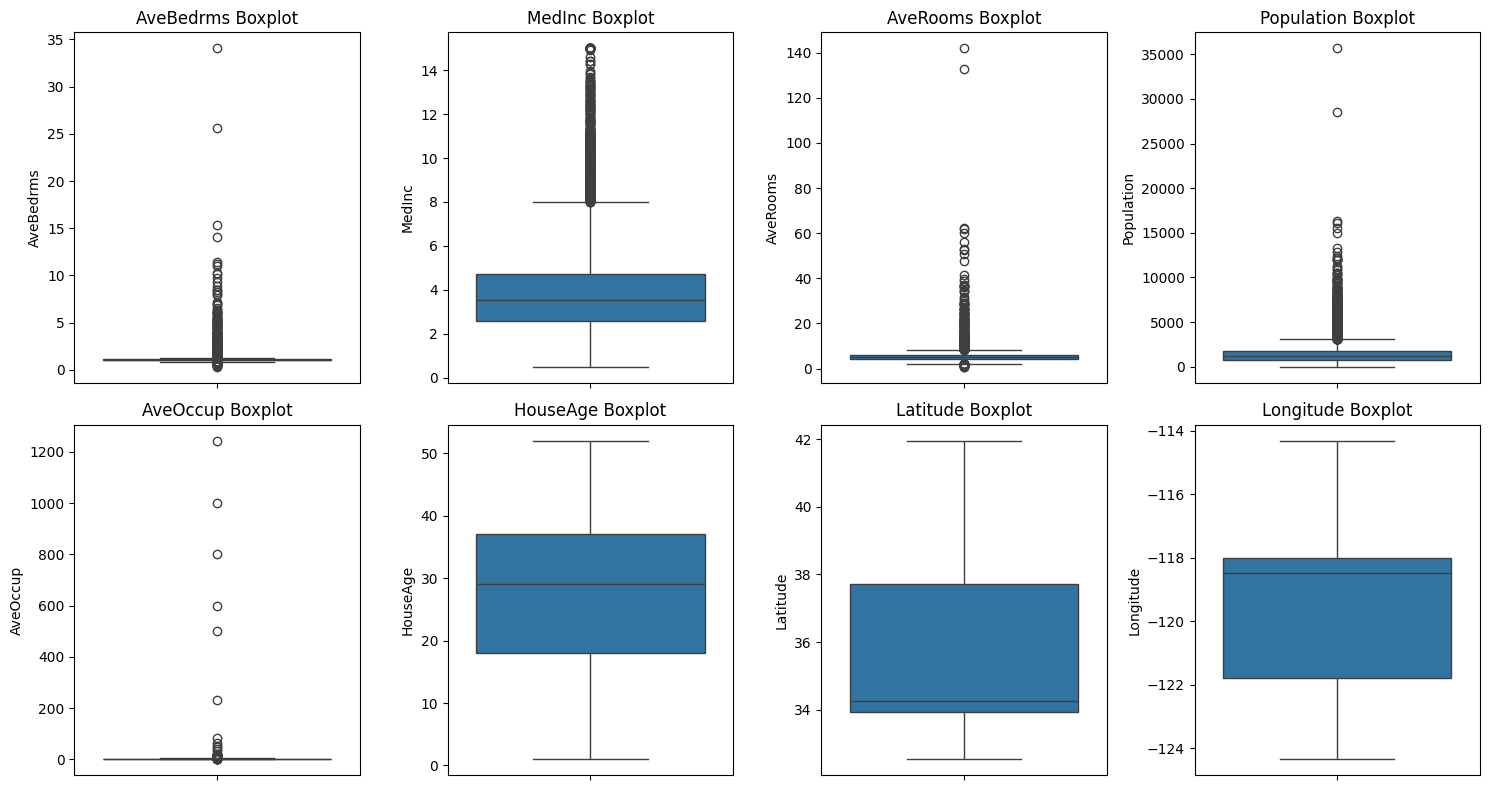

In [ ]:
#Boxplot for all variables
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
sns.boxplot(y=df["MedInc"], ax=axes[0][1])
axes[0][1].set_title('MedInc Boxplot')
sns.boxplot(y=df["HouseAge"], ax=axes[1][1])
axes[1][1].set_title('HouseAge Boxplot')
sns.boxplot(y=df["AveRooms"], ax=axes[0][2])
axes[0][2].set_title('AveRooms Boxplot')
sns.boxplot(y=df["AveBedrms"], ax=axes[0][0])
axes[0][0].set_title('AveBedrms Boxplot')
sns.boxplot(y=df["Population"], ax=axes[0][3])
axes[0][3].set_title('Population Boxplot')
sns.boxplot(y=df["AveOccup"], ax=axes[1][0])
axes[1][0].set_title('AveOccup Boxplot')
sns.boxplot(y=df["Latitude"], ax=axes[1][2])
axes[1][2].set_title('Latitude Boxplot')
sns.boxplot(y=df["Longitude"], ax=axes[1][3])
axes[1][3].set_title('Longitude Boxplot')
plt.tight_layout()
plt.show()

## 2. EDA and Feature Engineering

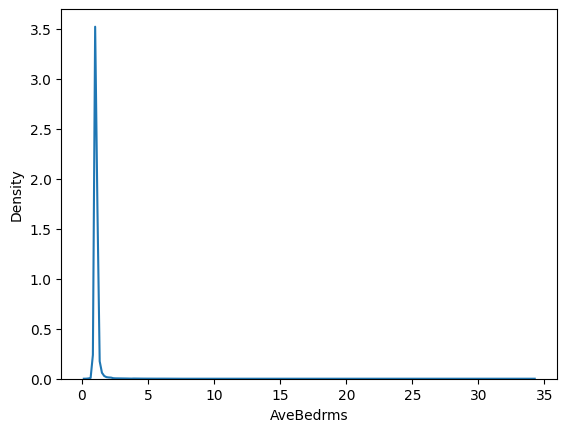

In [ ]:
#KDE of AVGberooms
sns.kdeplot(df["AveBedrms"].dropna())
plt.show()

In [ ]:
from scipy import stats
stats.shapiro()

In [ ]:
df.shape

(20640, 9)

In [ ]:
#Jarque_Bera test
from scipy.stats import jarque_bera
if jarque_bera(df["AveBedrms"])[1] < 0.05:
    print("The distribution is not normal")
else:
    print("The distribution is normal")

The distribution is normal


In [ ]:
#compute missing values using median
df["AveBedrms"] = df["AveBedrms"].fillna(np.median(df["AveBedrms"].dropna()))

In [ ]:
#check again
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [ ]:
#correct outliers using IQR for all variables
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

In [ ]:
for column in df.columns:
    lower_bound = Q1[column] - 1.5 * IQR[column]
    upper_bound = Q3[column] + 1.5 * IQR[column]

    # Cap the outliers
    df[column] = np.where(df[column] < lower_bound, lower_bound, df[column])
    df[column] = np.where(df[column] > upper_bound, upper_bound, df[column])

**Define Features and Target**

In [ ]:
#define X and y
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

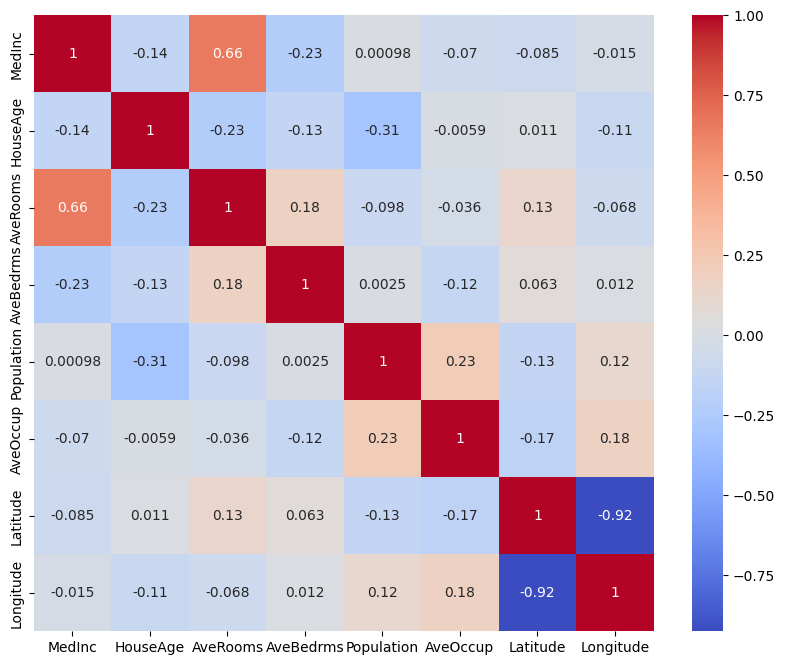

In [ ]:
#heatmap of X features
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm")
plt.show()

In [ ]:
#summary stats
X.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.801010,28.639486,5.304740,1.057956,1336.959012,2.899940,35.631861,-119.569704
std,1.657658,12.585558,1.246177,0.080440,765.550830,0.691437,2.135952,2.003532
min,0.499900,1.000000,2.023219,0.865961,3.000000,1.150851,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006100,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818463,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282334,37.710000,-118.010000
max,8.013025,52.000000,8.469878,1.239665,3132.000000,4.561224,41.950000,-114.310000


## 3. Linear Regression

In [ ]:
from sklearn.model_selection import train_test_split #randomly
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [ ]:
#Train Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 10)

In [ ]:
X_test

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20303,5.2783,12.0,4.466019,0.980583,405.0,3.932039,34.16,-119.18
16966,3.9722,27.0,4.619271,1.096357,1877.0,2.205640,37.55,-122.31
10623,4.5094,12.0,4.426380,1.092025,1913.0,1.956033,33.67,-117.77
6146,3.1034,29.0,4.597222,1.037037,2013.0,4.561224,34.11,-117.95
2208,4.6726,6.0,5.730303,1.033333,969.0,2.936364,36.81,-119.87
...,...,...,...,...,...,...,...,...
3263,2.2188,20.0,5.739796,1.178571,521.0,2.658163,39.14,-122.88
11694,7.1425,18.0,6.756322,1.004598,1278.0,2.937931,33.89,-117.98
1729,3.9773,33.0,4.716628,0.960187,1354.0,3.170960,37.98,-122.34
5087,0.9337,45.0,4.712329,1.139726,1382.0,3.786301,33.98,-118.28


In [ ]:
#fit the model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
model.coef_

array([ 4.95627687e-01,  1.29762665e-02, -1.03910810e-01,  1.90359637e+00,
        5.28316613e-05, -3.76222674e-01, -3.91061914e-01, -3.80575903e-01])

In [ ]:
model.intercept_

np.float64(-32.21048841968078)

In [ ]:
#calculate model prediction and coef
y_pred = model.predict(X_test)

In [ ]:
y_pred

array([2.50429984, 2.8488494 , 2.81756802, ..., 2.11236037, 0.89088248,
       4.06063425])

In [ ]:
pd.DataFrame({"Actual": y_test, "Predicted": y_pred})

,Actual,Predicted
20303,1.674000,2.504300
16966,3.541000,2.848849
10623,1.602000,2.817568
6146,1.408000,1.140473
2208,1.078000,1.725960
...,...,...
3263,1.063000,1.282301
11694,3.937000,3.382858
1729,1.313000,2.112360
5087,0.923000,0.890882


In [ ]:
#Test MSE, MAE, R_squared
print("Test MSE:", mean_squared_error(y_test, y_pred))
print("Test MAE:", np.mean(np.abs(y_test - y_pred)))
print("Test R_squared:", r2_score(y_test, y_pred))

Test MSE: 0.43537220745516764
Test MAE: 0.4871135550733041
Test R_squared: 0.6685385913694495


## 4. Predict Unkonwn prices

In [ ]:
data = pd.read_csv("HousePrice _un.csv")

In [ ]:
#predict
model.predict(data)